# Phase 11.1 - Offline RL mejorado (search + hybrid)

Búsqueda de hiperparámetros CQL y política híbrida CQL+behavior calibrada solo en validación temporal.

In [1]:
from pathlib import Path
import subprocess

ROOT = Path('.')
SCRIPT = ROOT / 'phases/phase11_offline_rl/run_phase11_1_offline_rl_improved.py'

res = subprocess.run(['python', str(SCRIPT)], cwd=ROOT, check=True, capture_output=True, text=True)
print(res.stdout)
if res.stderr:
    print(res.stderr)


Saved summary: ./phases/phase11_offline_rl/output_phase11_1_offline_rl_improved_GBPUSD/GBPUSD_phase11_1_summary.json
Best trial: t2_more_conservative
Holdout metrics: {'behavior': {'acc_action_3': 0.32619577308120135, 'f1_macro_action_3': 0.32455052218516484, 'avg_net_return': 0.00016313956810976485, 'cum_net_return': 0.5866498869227144, 'std_net_return': 0.004038152876353244, 'trade_rate': 0.3604004383087158, 'sharpe_ann': 3.14182826856007, 'win_rate_trades': 0.5478395061728395}, 'bc': {'acc_action_3': 0.3028364849833148, 'f1_macro_action_3': 0.2869690661163307, 'avg_net_return': 5.583476608995226e-05, 'cum_net_return': 0.20078181885946833, 'std_net_return': 0.0036740973621241556, 'trade_rate': 0.482480525970459, 'sharpe_ann': 1.1818433924490717, 'win_rate_trades': 0.5031700288184437}, 'cql': {'acc_action_3': 0.21273637374860957, 'f1_macro_action_3': 0.1860428755755965, 'avg_net_return': 8.857899048281425e-05, 'cum_net_return': 0.31853004977620003, 'std_net_return': 0.0021769895574479

In [2]:
import json
import pandas as pd
from IPython.display import display

OUT = ROOT / 'phases/phase11_offline_rl/output_phase11_1_offline_rl_improved_GBPUSD'
summary = json.loads((OUT / 'GBPUSD_phase11_1_summary.json').read_text())
trials = pd.read_csv(OUT / 'GBPUSD_phase11_1_trials.csv')
compare = pd.read_csv(OUT / 'GBPUSD_phase11_1_policy_comparison.csv')

print('Best trial:', summary['best_trial'])
print('Holdout metrics:', summary['holdout_metrics'])
print('Trials ranking:')
display(trials.sort_values('val_score_hybrid', ascending=False))
print('Policy comparison:')
display(compare)


Best trial: {'name': 't2_more_conservative', 'hidden_dim': 128, 'cql_alpha': 1.6, 'bc_reg': 0.01, 'q_lr': 0.0008, 'q_epochs': 50}
Holdout metrics: {'behavior': {'acc_action_3': 0.32619577308120135, 'f1_macro_action_3': 0.32455052218516484, 'avg_net_return': 0.00016313956810976485, 'cum_net_return': 0.5866498869227144, 'std_net_return': 0.004038152876353244, 'trade_rate': 0.3604004383087158, 'sharpe_ann': 3.14182826856007, 'win_rate_trades': 0.5478395061728395}, 'bc': {'acc_action_3': 0.3028364849833148, 'f1_macro_action_3': 0.2869690661163307, 'avg_net_return': 5.583476608995226e-05, 'cum_net_return': 0.20078181885946833, 'std_net_return': 0.0036740973621241556, 'trade_rate': 0.482480525970459, 'sharpe_ann': 1.1818433924490717, 'win_rate_trades': 0.5031700288184437}, 'cql': {'acc_action_3': 0.21273637374860957, 'f1_macro_action_3': 0.1860428755755965, 'avg_net_return': 8.857899048281425e-05, 'cum_net_return': 0.31853004977620003, 'std_net_return': 0.002176989557447994, 'trade_rate': 0.

,trial,hidden_dim,cql_alpha,bc_reg,q_lr,q_epochs,val_score_hybrid,val_avg_hybrid,val_sharpe_hybrid,holdout_avg_hybrid,holdout_cum_hybrid,holdout_sharpe_hybrid,holdout_cum_behavior,holdout_cum_bc,holdout_cum_cql,hybrid_override_conf,hybrid_inf_min
2,t2_more_conservative,128,1.6,0.01,0.0008,50,3.143588,0.000274,3.989867,0.000163,0.586650,3.141828,0.58665,0.200782,0.318530,0.70,0.3
0,t0_baseline_like,96,1.2,0.03,0.0008,45,3.109351,0.000271,3.947130,0.000163,0.586650,3.141828,0.58665,0.489742,0.331661,0.45,0.5
1,t1_less_conservative,128,0.8,0.02,0.0010,50,2.923760,0.000255,3.688329,0.000130,0.469217,2.425345,0.58665,0.341889,0.296783,0.60,0.5
3,t3_wider_model,160,1.0,0.01,0.0007,60,2.887623,0.000252,3.651418,0.000163,0.586199,3.139405,0.58665,0.460958,0.280079,0.40,0.5


Policy comparison:


,split,policy,acc_action_3,f1_macro_action_3,avg_net_return,cum_net_return,std_net_return,trade_rate,sharpe_ann,win_rate_trades
0,validation,behavior,0.337427,0.332445,0.000228,0.390024,0.005181,0.361988,3.423678,0.531502
1,validation,bc,0.263743,0.244683,0.000274,0.468178,0.004759,0.195906,4.474023,0.561194
2,validation,cql,0.213450,0.172737,0.000267,0.456089,0.004183,0.084211,4.958440,0.604167
3,validation,hybrid_cql_behavior,0.339766,0.335434,0.000274,0.469327,0.005350,0.368421,3.989867,0.533333
4,holdout,behavior,0.326196,0.324551,0.000163,0.586650,0.004038,0.360400,3.141828,0.547840
5,holdout,bc,0.302836,0.286969,0.000056,0.200782,0.003674,0.482481,1.181843,0.503170
6,holdout,cql,0.212736,0.186043,0.000089,0.318530,0.002177,0.115128,3.164319,0.596618
7,holdout,hybrid_cql_behavior,0.326196,0.324551,0.000163,0.586650,0.004038,0.360400,3.141828,0.547840


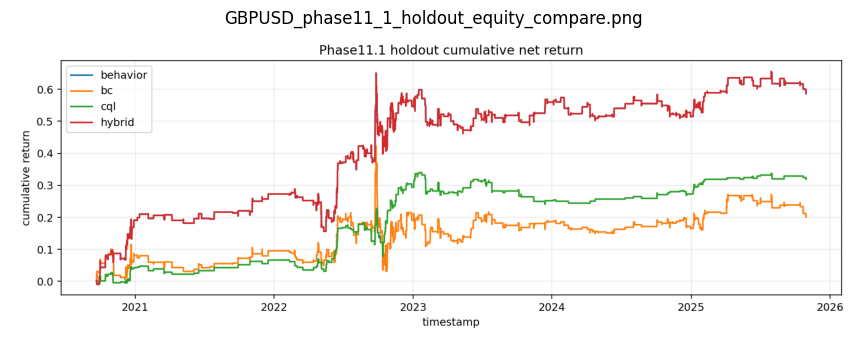

In [3]:
import matplotlib.pyplot as plt
img = plt.imread(OUT / 'GBPUSD_phase11_1_holdout_equity_compare.png')
plt.figure(figsize=(12, 4))
plt.imshow(img)
plt.axis('off')
plt.title('GBPUSD_phase11_1_holdout_equity_compare.png')
plt.show()
